In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.studies.italy_productivity.analysis.data import *
from cifresignificative.core.viz.style import *
apply_style()
panel = load_panel()


# 06 - Correlations, panel regression, and which countries look like Italy
Associations, not causal claims.

,2005-09,2015-19,2020-24
Real GDP per head,0.5,0.3,0.3
GDP growth,-1.4,-1.0,-0.1
Investment % GDP,-0.5,-0.8,-0.3
Public investment % GDP,-1.1,-1.3,-0.9
R&D % GDP,-0.1,0.1,-0.1
Government debt % GDP,2.5,2.0,2.4
Interest % GDP,2.4,2.4,3.2
10y yield,-0.0,0.8,0.7
Inflation,-0.3,-1.0,-0.4
Employment 20-64,-1.7,-2.0,-2.8


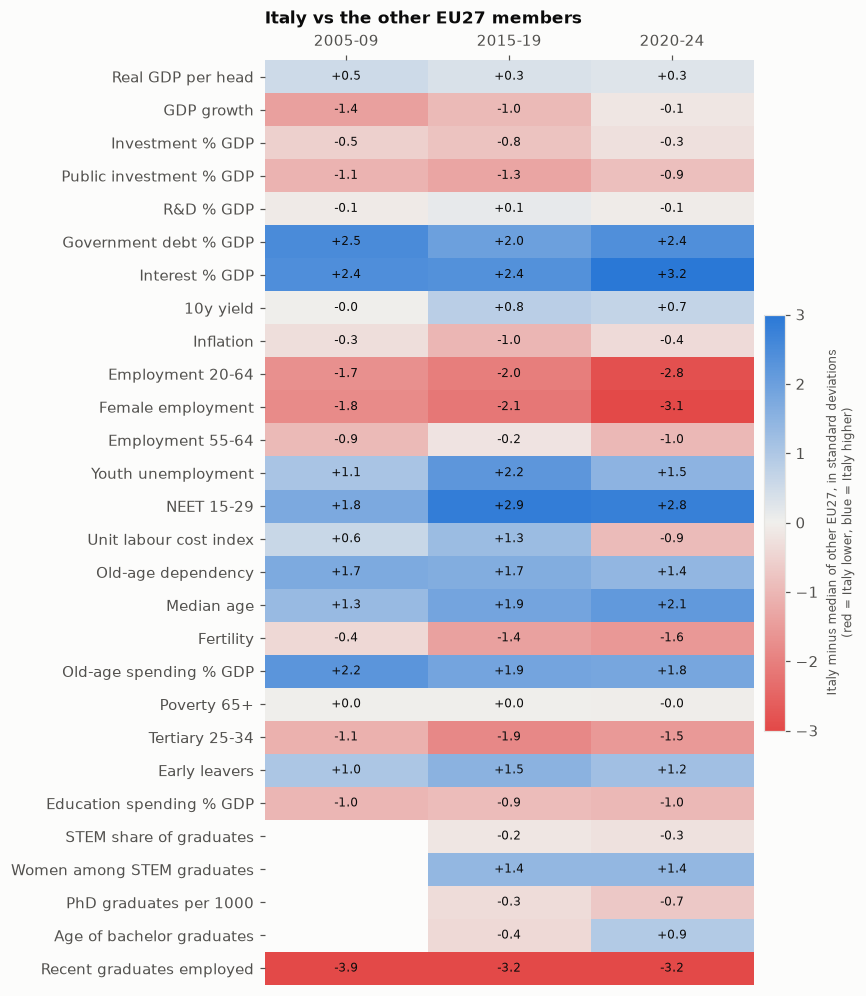

In [2]:
# 1) Where does Italy sit? Gap vs the median of other EU27, in standard deviations, three periods
groups = {g: it for g, it in GAP_GROUPS.items() if g not in ("Gender & wages", "Governance")}  # shared definition (cifresignificative.studies.italy_productivity.analysis.data); the two newer groups are shown in notebooks 09 and 11
windows = {"2005-09": (2005, 2009), "2015-19": (2015, 2019), "2020-24": (2020, 2024)}
rows = {}
for grp, items in groups.items():
    for ind, label in items:
        rows[(grp, label)] = {k: zscore_gap(panel, [ind], w).get(ind, np.nan) for k, w in windows.items()}
gaps = pd.DataFrame(rows).T
gaps.index = [f"{l}" for g, l in gaps.index]
gap_heatmap(gaps, "Italy vs the other EU27 members", name="06_gap_heatmap")
display(gaps.round(1))

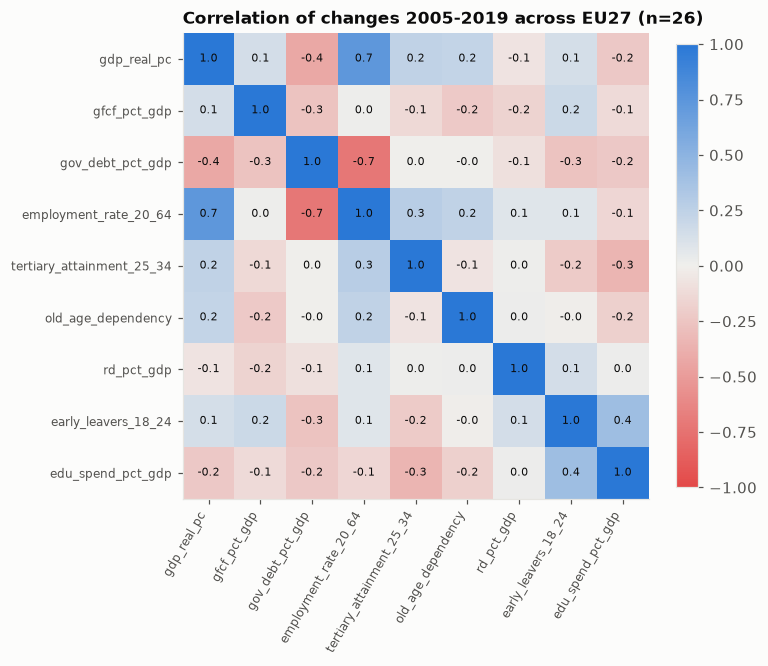

In [3]:
# 2) Cross-country correlations of changes 2005-2019 -> are faster-growing countries different?
inds = ["gdp_real_pc", "gfcf_pct_gdp", "gov_debt_pct_gdp", "employment_rate_20_64", "tertiary_attainment_25_34", "old_age_dependency", "rd_pct_gdp", "early_leavers_18_24", "edu_spend_pct_gdp"]
ch = {}
for ind in inds:
    w = wide(panel, ind, EU27_ISO3)
    ch[ind] = (np.log(w.loc[2019] / w.loc[2005]) * 100) if ind == "gdp_real_pc" else (w.loc[2019] - w.loc[2005])
ch = pd.DataFrame(ch).dropna()
corr = ch.corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5)); im = ax.imshow(corr.values, cmap=DIVERGING, vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(inds)), inds, rotation=60, ha="right", fontsize=8); ax.set_yticks(range(len(inds)), inds, fontsize=8)
for i in range(len(inds)):
    for j in range(len(inds)): ax.text(j, i, f"{corr.values[i, j]:.1f}", ha="center", va="center", fontsize=7)
ax.set_title("Correlation of changes 2005-2019 across EU27 (n=%d)" % len(ch)); fig.colorbar(im, ax=ax, fraction=0.04); save(fig, "06_change_correlations")

In [4]:
# 3) Panel regression with country and year fixed effects: annual real growth on lagged levels (EU27, 2006-2024)
from linearmodels.panel import PanelOLS
vars_ = {"gov_debt_pct_gdp": "debt/GDP (lag)", "gfcf_pct_gdp": "investment/GDP (lag)", "employment_rate_20_64": "employment rate (lag)",
         "tertiary_attainment_25_34": "tertiary 25-34 (lag)", "old_age_dependency": "old-age dependency (lag)"}
d = panel[panel.iso3.isin(EU27_ISO3) & panel.year.between(2005, 2024)]
wide_all = d.pivot_table(index=["iso3", "year"], columns="indicator", values="value")
X = wide_all[list(vars_)].groupby(level=0).shift(1).rename(columns=vars_)
df = pd.concat([wide_all["gdp_growth"].rename("growth"), X], axis=1).dropna()
out = {}
for lab, sub in [("all EU27", df), ("excluding Ireland", df[~df.index.get_level_values("iso3").isin(["IRL"])])]:
    r = PanelOLS(sub["growth"], sub.drop(columns="growth"), entity_effects=True, time_effects=True).fit(cov_type="clustered", cluster_entity=True)
    out[lab] = pd.DataFrame({"coef": r.params, "p": r.pvalues}).round(3).assign(n=int(r.nobs), within_R2=round(r.rsquared_within, 3))
tab = pd.concat(out, axis=1); display(tab)
res = r  # last fit (excluding Ireland), used in the line below
print("n (excluding Ireland) =", int(res.nobs), "| within R2 =", round(res.rsquared_within, 3))

all EU27                       excluding Ireland  \
                             coef      p    n within_R2              coef   
debt/GDP (lag)              0.037  0.143  513     0.031             0.014   
investment/GDP (lag)        0.209  0.020  513     0.031             0.081   
employment rate (lag)      -0.068  0.439  513     0.031            -0.059   
tertiary 25-34 (lag)        0.047  0.328  513     0.031             0.040   
old-age dependency (lag)    0.199  0.121  513     0.031             0.176   

                                                
                              p    n within_R2  
debt/GDP (lag)            0.480  494     0.015  
investment/GDP (lag)      0.180  494     0.015  
employment rate (lag)     0.515  494     0.015  
tertiary 25-34 (lag)      0.383  494     0.015  
old-age dependency (lag)  0.169  494     0.015

n (excluding Ireland) = 494 | within R2 = 0.015


Closest profiles to Italy: {'GRC': 3.5, 'FRA': 3.73, 'ESP': 3.73, 'PRT': 4.39, 'ROU': 4.46} 
Furthest: {'LUX': 7.91, 'SWE': 8.08, 'IRL': 8.67}


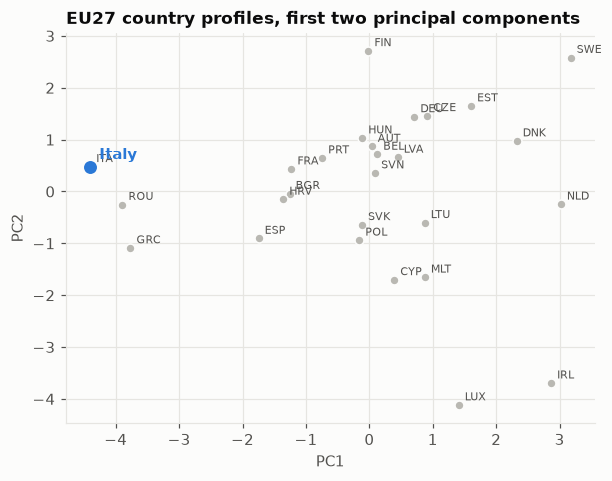

In [5]:
# 4) Which countries look most like Italy? Euclidean distance on standardized 2022-24 profile (EU27)
prof = ["gdp_real_pc", "gov_debt_pct_gdp", "gfcf_pct_gdp", "employment_rate_20_64", "employment_rate_55_64", "old_age_dependency", "pension_spend_pct_gdp", "tertiary_attainment_25_34", "early_leavers_18_24", "neet_rate_15_29", "edu_spend_pct_gdp", "rd_pct_gdp"]
P = pd.DataFrame({i: wide(panel, i, EU27_ISO3).loc[2022:2024].mean() for i in prof}).dropna()
Z = (P - P.mean()) / P.std()
dist = ((Z - Z.loc[ITALY]) ** 2).sum(axis=1).pow(0.5).drop(ITALY).sort_values()
from sklearn.decomposition import PCA
pcs = pd.DataFrame(PCA(2).fit_transform(Z), index=Z.index, columns=["PC1", "PC2"])
fig, ax = plt.subplots(figsize=(6.2, 4.6)); ax.scatter(pcs.PC1, pcs.PC2, color=PEER_C, s=34, edgecolor=SURFACE)
for c, r in pcs.iterrows(): ax.annotate(c, (r.PC1, r.PC2), xytext=(4, 3), textcoords="offset points", fontsize=7, color=INK2)
ax.scatter(*pcs.loc[ITALY], color=ITALY_C, s=90, zorder=4, edgecolor=SURFACE); ax.annotate("Italy", pcs.loc[ITALY], xytext=(6, 5), textcoords="offset points", color=ITALY_C, fontweight="bold")
ax.set_title("EU27 country profiles, first two principal components"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); save(fig, "06_pca_profiles")
print("Closest profiles to Italy:", dist.head(5).round(2).to_dict(), "\nFurthest:", dist.tail(3).round(2).to_dict())

## Takeaways
- **Italy's profile against the other EU27 (heatmap, 2020-24):** furthest below the median on employment (-2.8 sd) and female employment (-3.1 sd); furthest above on interest costs (+3.2), debt (+2.4), NEET (+2.8), old-age spending (+1.8) and old-age dependency (+1.4); also below on tertiary attainment (-1.5) and education spending (-1.0). GDP per head is slightly *above* the median (+0.3) and R&D, 10-year yields, and 65+ poverty are close to it.
- **Growth regression is weak and fragile:** with country and year fixed effects, lagged investment/GDP appears significant (+0.21 pp growth per pp, p=0.02) only when Ireland is included; excluding Ireland (whose GDP is dominated by multinational accounting) it is +0.08 (p=0.18), and no regressor is significant in either 3-year or 5-year windows (notebook 20). Treat the regression as showing no robust association rather than a finding about investment.
- **Peer countries by profile:** Greece, France, Spain, Portugal and Romania are closest to Italy; Luxembourg, Sweden and Ireland are furthest.